<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/PRV_2026_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/PRV_metaheuristicas_duas_estrategias.ipynb" target="_parent">
<img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


# Problema de Roteamento de Veículos — Metaheurísticas de Trajetória com Duas Representações

Neste notebook estudaremos **Recozimento Simulado (SA)** e **Busca Tabu** para uma
versão simplificada do Problema de Roteamento de Veículos.

O objetivo principal será comparar duas maneiras de representar e construir as soluções:

### Estratégia A — Split-first / Route-second

$$
\boxed{
\text{dividir clientes entre veículos}
\rightarrow
\text{construir uma rota em cada grupo}
}
$$

A solução manipulada pela metaheurística é diretamente um conjunto de rotas.

### Estratégia B — Route-first / Split-second

$$
\boxed{
\text{construir uma única ordem dos clientes}
\rightarrow
\text{Split ótimo}
}
$$

A metaheurística manipula somente uma permutação — a **giant tour** — e um algoritmo
de programação dinâmica encontra a melhor divisão dessa ordem entre os veículos.

> Neste notebook, o termo **split-first** da primeira estratégia significa uma
> divisão heurística dos clientes em grupos. Já **Split** com maiúscula, na segunda
> estratégia, refere-se ao algoritmo exato de programação dinâmica.


## Objetivos

Ao final do notebook, esperamos compreender:

- como a representação da solução altera o espaço de busca;
- como definir movimentos diretamente sobre rotas;
- como aplicar SA e Busca Tabu a rotas explícitas;
- como representar uma solução por uma única permutação;
- como utilizar o algoritmo Split como decoder ótimo;
- como aplicar SA e Busca Tabu sobre permutações;
- quais são os trade-offs entre custo por avaliação e flexibilidade da representação.


In [1]:
import collections
import copy
import itertools
import math
import random
import statistics
import time

import matplotlib.pyplot as plt
import numpy as np


# 1. Definição do problema

Consideraremos um grafo completo com:

- um depósito;
- $n$ clientes;
- exatamente $R$ veículos;
- custos dados pela distância euclidiana.

Todos os clientes devem ser visitados exatamente uma vez e todas as rotas começam
e terminam no depósito.

Neste notebook **não consideraremos capacidades**. O uso de exatamente $R$ rotas
não vazias evita a degeneração em que uma única rota atenderia todos os clientes.

A versão capacitada será retomada no notebook de Algoritmos Genéticos.


In [2]:
distancia = math.dist


def tamanho_rota(rota):
    """
    A rota é armazenada sem repetir o depósito ao final.
    O termo rota[i-1] fecha automaticamente o ciclo.
    """
    if len(rota) <= 1:
        return 0.0

    return sum(
        distancia(rota[i - 1], rota[i])
        for i in range(len(rota))
    )


class PRV:
    def __init__(self):
        self.clientes = []   # clientes[0] é o depósito
        self.R = 0
        self.rotas = []

    def custo(self):
        return sum(
            tamanho_rota(rota)
            for rota in self.rotas
        )

    def __repr__(self):
        return (
            f"Clientes={len(self.clientes)-1} | "
            f"Veículos={self.R} | "
            f"Custo={self.custo():.2f}"
        )


### Convenção de representação

Uma rota

```python
[deposito, cliente_1, cliente_2, cliente_3]
```

representa o ciclo

$$
D\rightarrow1\rightarrow2\rightarrow3\rightarrow D.
$$

O depósito não precisa ser repetido no final da lista.


In [3]:
def gerar_prv(
    n,
    r,
    largura=900,
    altura=900,
    rseed=233
):
    if n < r:
        raise ValueError(
            "É necessário ter pelo menos um cliente por veículo."
        )

    rng = random.Random(rseed)

    prv = PRV()
    prv.R = r

    prv.clientes = [
        [rng.randrange(largura), rng.randrange(altura)]
        for _ in range(n + 1)
    ]

    prv.clientes[0] = [
        largura // 2,
        altura // 2
    ]

    return prv


In [4]:
def plot_prv(prv, titulo=None):
    print(prv)

    plt.figure(figsize=(8, 6))

    cmap = plt.get_cmap("tab10")

    for indice_rota, rota in enumerate(prv.rotas):
        if not rota:
            continue

        caminho = rota + [rota[0]]

        x = [p[0] for p in caminho]
        y = [p[1] for p in caminho]

        plt.plot(
            x,
            y,
            marker="o",
            linewidth=2,
            label=f"Rota {indice_rota + 1}",
            color=cmap(indice_rota % 10)
        )

    deposito = prv.clientes[0]

    plt.scatter(
        [deposito[0]],
        [deposito[1]],
        marker="D",
        s=120,
        edgecolor="black",
        label="Depósito"
    )

    plt.axis("scaled")
    plt.legend()

    if titulo:
        plt.title(titulo)

    plt.show()


In [5]:
instancia = gerar_prv(
    n=30,
    r=3,
    rseed=2026
)

print(instancia)


Clientes=30 | Veículos=3 | Custo=0.00


# 2. Estratégia A — Split-first / Route-second

Nesta primeira estratégia tomamos duas decisões separadamente:

1. **Split-first:** dividimos os clientes em $R$ grupos;
2. **Route-second:** construímos uma rota dentro de cada grupo.

Utilizaremos:

- K-Means para a divisão inicial;
- vizinho mais próximo para ordenar cada grupo.

Depois disso, SA e Busca Tabu atuarão **diretamente sobre as rotas**.

Essa é uma representação muito intuitiva:

$$
S=(r_1,r_2,\ldots,r_R).
$$


## 2.1 Construção inicial

O K-Means não minimiza diretamente a distância de roteamento. Ele apenas procura
grupos espacialmente compactos.

Por isso ele funciona aqui como uma **heurística de particionamento inicial**.

Depois de criar os grupos, aplicamos o vizinho mais próximo dentro de cada um.


In [6]:
def _reparar_grupos_vazios(
    grupos,
    centroides
):
    vazios = [
        g
        for g, grupo in enumerate(grupos)
        if len(grupo) == 0
    ]

    for grupo_vazio in vazios:
        doadores = [
            g
            for g, grupo in enumerate(grupos)
            if len(grupo) > 1
        ]

        if not doadores:
            raise RuntimeError(
                "Não foi possível reparar os grupos."
            )

        doador = max(
            doadores,
            key=lambda g: len(grupos[g])
        )

        centro = centroides[doador]

        posicao = max(
            range(len(grupos[doador])),
            key=lambda p: distancia(
                grupos[doador][p],
                centro
            )
        )

        cliente = grupos[doador].pop(posicao)
        grupos[grupo_vazio].append(cliente)

    return grupos


def kmeans(
    prv,
    max_iter=100,
    rseed=1234
):
    S = copy.deepcopy(prv)

    clientes = S.clientes[1:]

    rng = random.Random(rseed)

    centroides = [
        np.array(c, dtype=float)
        for c in rng.sample(
            clientes,
            S.R
        )
    ]

    for _ in range(max_iter):
        grupos = [
            []
            for _ in range(S.R)
        ]

        for cliente in clientes:
            dists = [
                distancia(
                    cliente,
                    centro
                )
                for centro in centroides
            ]

            grupos[
                int(np.argmin(dists))
            ].append(cliente)

        grupos = _reparar_grupos_vazios(
            grupos,
            centroides
        )

        novos_centroides = [
            np.mean(
                grupo,
                axis=0
            )
            for grupo in grupos
        ]

        S.rotas = grupos

        if np.allclose(
            centroides,
            novos_centroides
        ):
            break

        centroides = novos_centroides

    return S


def mais_proxima(
    cidade,
    candidatas
):
    return min(
        candidatas,
        key=lambda x: distancia(
            cidade,
            x
        )
    )


def vizinho_mais_proximo(
    cidades
):
    primeira = cidades[0]

    rota = [primeira]
    restantes = cidades[1:].copy()

    while restantes:
        proxima = mais_proxima(
            rota[-1],
            restantes
        )

        rota.append(proxima)
        restantes.remove(proxima)

    return rota


def solucao_inicial_split_route(
    prv,
    rseed=1234
):
    S = kmeans(
        prv,
        rseed=rseed
    )

    for i in range(S.R):
        S.rotas[i] = vizinho_mais_proximo(
            [S.clientes[0]]
            + S.rotas[i]
        )

    return S


Clientes=30 | Veículos=3 | Custo=6082.38


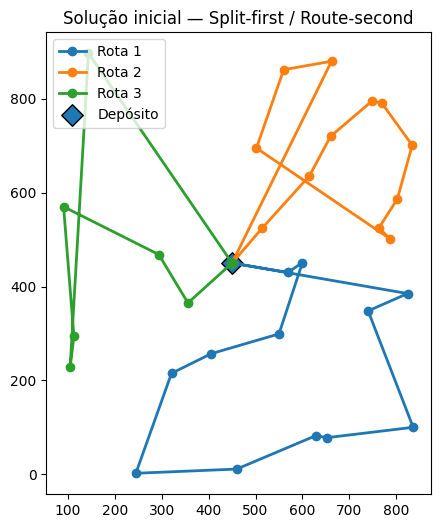

In [7]:
S0_rotas = solucao_inicial_split_route(
    instancia,
    rseed=10
)

plot_prv(
    S0_rotas,
    "Solução inicial — Split-first / Route-second"
)


## 2.2 Movimentos sobre rotas

Utilizaremos três movimentos clássicos:

- **swap:** troca dois clientes;
- **relocate:** remove um cliente e o reinsere antes de outro;
- **inversão:** inverte um segmento dentro de uma rota.

Esses movimentos podem alterar tanto a ordem das visitas quanto a distribuição dos
clientes entre os veículos.


In [8]:
def encontrar_cliente(
    S,
    indice_cliente
):
    cliente = S.clientes[
        indice_cliente
    ]

    for indice_rota, rota in enumerate(
        S.rotas
    ):
        try:
            posicao = rota.index(
                cliente
            )

            return (
                indice_rota,
                posicao
            )

        except ValueError:
            continue

    raise ValueError(
        f"Cliente {indice_cliente} não encontrado."
    )


def trocar_clientes(
    S,
    i,
    j
):
    ri, pi = encontrar_cliente(S, i)
    rj, pj = encontrar_cliente(S, j)

    S.rotas[ri][pi], S.rotas[rj][pj] = (
        S.rotas[rj][pj],
        S.rotas[ri][pi]
    )

    return S


def inverter_segmento_rota(
    S,
    i,
    j
):
    ri, pi = encontrar_cliente(S, i)
    rj, pj = encontrar_cliente(S, j)

    if ri != rj:
        return S

    a, b = sorted(
        (pi, pj)
    )

    S.rotas[ri][a:b + 1] = reversed(
        S.rotas[ri][a:b + 1]
    )

    return S


def realocar_cliente(
    S,
    cliente_movido,
    cliente_referencia
):
    origem, pos_origem = encontrar_cliente(
        S,
        cliente_movido
    )

    destino, pos_destino = encontrar_cliente(
        S,
        cliente_referencia
    )

    # Não podemos deixar uma rota sem clientes:
    # [deposito, unico_cliente].
    if (
        origem != destino
        and len(S.rotas[origem]) <= 2
    ):
        return S

    cliente = S.rotas[origem].pop(
        pos_origem
    )

    if (
        origem == destino
        and pos_origem < pos_destino
    ):
        pos_destino -= 1

    S.rotas[destino].insert(
        pos_destino,
        cliente
    )

    return S


def vizinho_rotas_aleatorio(
    S,
    rng
):
    R = copy.deepcopy(S)

    operador = rng.choice(
        ["swap", "relocate", "reverse"]
    )

    i, j = rng.sample(
        range(1, len(S.clientes)),
        2
    )

    if operador == "swap":
        trocar_clientes(
            R,
            i,
            j
        )

    elif operador == "relocate":
        realocar_cliente(
            R,
            i,
            j
        )

    else:
        ri, _ = encontrar_cliente(R, i)
        rj, _ = encontrar_cliente(R, j)

        if ri == rj:
            inverter_segmento_rota(
                R,
                i,
                j
            )
        else:
            # Se os clientes estão em rotas diferentes,
            # usamos swap como movimento alternativo.
            trocar_clientes(
                R,
                i,
                j
            )

    return R


## 2.3 Recozimento Simulado sobre rotas

O estado corrente é o próprio conjunto de rotas.

Geramos uma solução vizinha, calculamos

$$
\Delta=f(S')-f(S),
$$

e aceitamos:

- sempre, se $\Delta\leq0$;
- com probabilidade

$$
\exp(-\Delta/T)
$$

quando há piora.


In [9]:
def temperatura_geometrica(
    prv,
    iteracao,
    fator_resfriamento=0.999
):
    temperatura_inicial = (
        len(prv.clientes) ** 2
    )

    return (
        temperatura_inicial
        * fator_resfriamento ** iteracao
    )


def sa_rotas(
    prv,
    tempo_max=2.0,
    iter_max=100000,
    fator_resfriamento=0.999,
    seed=1
):
    rng = random.Random(seed)

    atual = solucao_inicial_split_route(
        prv,
        rseed=seed
    )

    melhor = copy.deepcopy(
        atual
    )

    inicio = time.perf_counter()
    historico = []

    iteracao = 0

    while (
        iteracao < iter_max
        and time.perf_counter() - inicio < tempo_max
    ):
        iteracao += 1

        temperatura = temperatura_geometrica(
            prv,
            iteracao,
            fator_resfriamento
        )

        candidata = vizinho_rotas_aleatorio(
            atual,
            rng
        )

        delta = (
            candidata.custo()
            - atual.custo()
        )

        aceitou = (
            delta <= 0
            or rng.random()
            < math.exp(
                -delta
                / max(temperatura, 1e-12)
            )
        )

        if aceitou:
            atual = candidata

            if (
                atual.custo()
                < melhor.custo()
            ):
                melhor = copy.deepcopy(
                    atual
                )

        historico.append({
            "iteracao": iteracao,
            "custo_atual": atual.custo(),
            "melhor_custo": melhor.custo(),
            "temperatura": temperatura
        })

    return (
        melhor,
        historico
    )


SA — rotas explícitas: 4766.5830548066515
Clientes=30 | Veículos=3 | Custo=4766.58


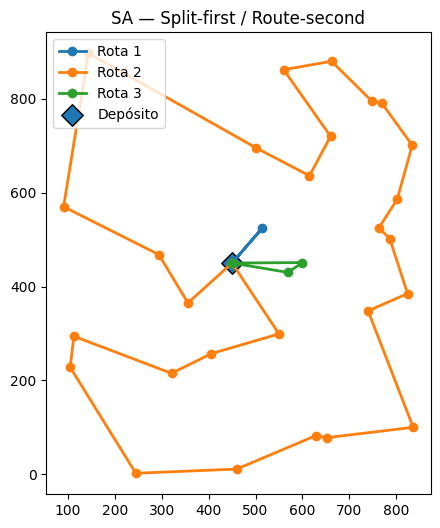

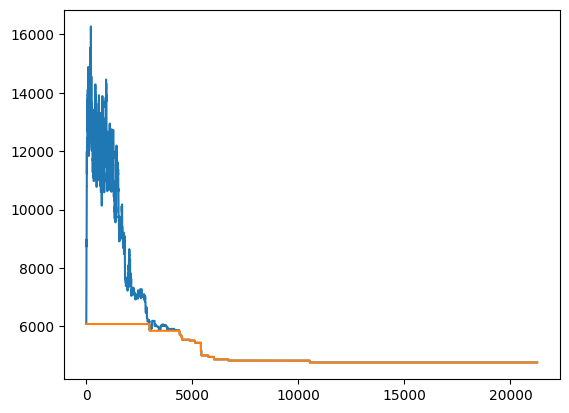

In [37]:
S_sa_rotas, hist_sa_rotas = sa_rotas(
    instancia,
    tempo_max=5,
    seed=10
)

print(
    "SA — rotas explícitas:",
    S_sa_rotas.custo()
)

plot_prv(
    S_sa_rotas,
    "SA — Split-first / Route-second"
)

plt.plot(
    [h["iteracao"] for h in hist_sa_rotas],
    [h["custo_atual"] for h in hist_sa_rotas],
    label="SA — rotas"
)

plt.plot(
    [h["iteracao"] for h in hist_sa_rotas],
    [h["melhor_custo"] for h in hist_sa_rotas],
    label="SA — rotas"
)


## 2.4 Busca Tabu sobre rotas

Na Busca Tabu examinamos uma vizinhança explícita.

Para manter o código didático, associaremos a cada par de clientes um movimento:

- clientes na mesma rota → inversão;
- clientes em rotas diferentes → relocate.

A lista tabu armazena os pares utilizados recentemente.

Também utilizaremos um **critério de aspiração**: um movimento tabu pode ser aceito
se produzir uma nova melhor solução global.


In [11]:
def movimento_rotas(
    S,
    i,
    j
):
    R = copy.deepcopy(S)

    ri, _ = encontrar_cliente(
        R,
        i
    )

    rj, _ = encontrar_cliente(
        R,
        j
    )

    if ri == rj:
        inverter_segmento_rota(
            R,
            i,
            j
        )

        tipo = "reverse"

    else:
        realocar_cliente(
            R,
            i,
            j
        )

        tipo = "relocate"

    return (
        R,
        (tipo, i, j)
    )


def vizinhanca_tabu_rotas(
    S,
    tabu,
    melhor_custo
):
    candidatos = []

    n = len(S.clientes) - 1

    for i in range(1, n + 1):
        for j in range(1, n + 1):
            if i == j:
                continue

            R, movimento = movimento_rotas(
                S,
                i,
                j
            )

            atributo_tabu = movimento in tabu

            aspiracao = (
                R.custo()
                < melhor_custo
            )

            if (
                not atributo_tabu
                or aspiracao
            ):
                candidatos.append(
                    (
                        R,
                        movimento
                    )
                )

    return candidatos


def tabu_rotas(
    prv,
    tempo_max=2.0,
    tamanho_tabu=8,
    iter_max=10000,
    seed=1
):
    # seed é usado na construção inicial.
    atual = solucao_inicial_split_route(
        prv,
        rseed=seed
    )

    melhor = copy.deepcopy(
        atual
    )

    tabu = collections.deque(
        maxlen=tamanho_tabu
    )

    inicio = time.perf_counter()
    historico = []

    iteracao = 0

    while (
        iteracao < iter_max
        and time.perf_counter() - inicio < tempo_max
    ):
        iteracao += 1

        vizinhos = vizinhanca_tabu_rotas(
            atual,
            tabu,
            melhor.custo()
        )

        if not vizinhos:
            break

        candidata, movimento = min(
            vizinhos,
            key=lambda item: item[0].custo()
        )

        atual = candidata

        if (
            atual.custo()
            < melhor.custo()
        ):
            melhor = copy.deepcopy(
                atual
            )

        tabu.append(
            movimento
        )

        historico.append({
            "iteracao": iteracao,
            "custo_atual": atual.custo(),
            "melhor_custo": melhor.custo(),
            "movimento": movimento
        })

    return (
        melhor,
        historico
    )


Tabu — rotas explícitas: 5253.073939130549
Clientes=30 | Veículos=3 | Custo=5253.07


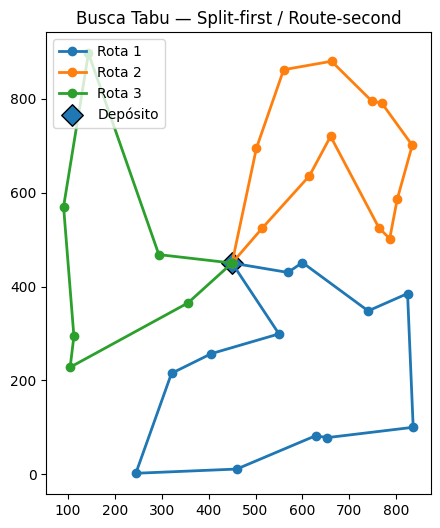

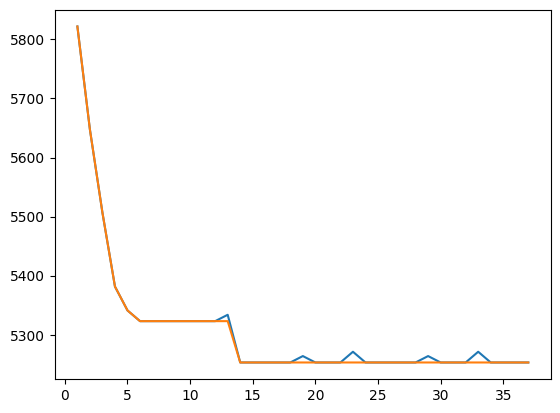

In [33]:
S_tabu_rotas, hist_tabu_rotas = tabu_rotas(
    instancia,
    tempo_max=5,
    tamanho_tabu=8,
    seed=10
)

print(
    "Tabu — rotas explícitas:",
    S_tabu_rotas.custo()
)

plot_prv(
    S_tabu_rotas,
    "Busca Tabu — Split-first / Route-second"
)

plt.plot(
    [h["iteracao"] for h in hist_tabu_rotas],
    [h["custo_atual"] for h in hist_tabu_rotas],
    label="Tabu — rotas"
)

plt.plot(
    [h["iteracao"] for h in hist_tabu_rotas],
    [h["melhor_custo"] for h in hist_tabu_rotas],
    label="Tabu — rotas"
)


# 3. Estratégia B — Route-first / Split-second

Agora mudaremos completamente a representação.

A metaheurística não manipulará mais $R$ rotas diretamente.

Em vez disso, armazenamos uma única permutação:

$$
\pi=(\pi_1,\pi_2,\ldots,\pi_n),
$$

chamada de **giant tour**.

O algoritmo Split determina onde inserir $R-1$ separadores.

Assim,

$$
\boxed{
\text{metaheurística}
\rightarrow
\text{ordem dos clientes}
}
$$

e

$$
\boxed{
\text{Split}
\rightarrow
\text{melhor divisão daquela ordem}
}.
$$


## 3.1 Split ótimo

Para uma permutação fixa $\pi$, defina

$$
C(i,j)
$$

como o custo da rota

$$
D\rightarrow\pi_i\rightarrow\cdots\rightarrow\pi_j\rightarrow D.
$$

Defina também

$$
F(k,j)
$$

como o menor custo para atender os primeiros $j$ clientes usando exatamente
$k$ veículos.

A recorrência é

$$
F(k,j)
=
\min_{i=k-1,\ldots,j-1}
\left\{
F(k-1,i)+C(i+1,j)
\right\}.
$$

O valor $F(R,n)$ fornece a melhor divisão da permutação em exatamente $R$
rotas não vazias.


In [13]:
def split_otimo(
    prv,
    permutacao
):
    perm = list(
        map(int, permutacao)
    )

    n = len(perm)
    R = prv.R

    esperado = set(
        range(1, len(prv.clientes))
    )

    if (
        len(perm) != len(esperado)
        or set(perm) != esperado
    ):
        raise ValueError(
            "A permutação deve conter cada cliente exatamente uma vez."
        )

    if R > n:
        raise ValueError(
            "Número de veículos maior que o número de clientes."
        )

    deposito = prv.clientes[0]

    # ---------------------------------------------------------
    # Custos C(i,j)
    # ---------------------------------------------------------
    custo_segmento = [
        [float("inf")] * n
        for _ in range(n)
    ]

    for i in range(n):
        custo = distancia(
            deposito,
            prv.clientes[perm[i]]
        )

        for j in range(i, n):
            if j > i:
                custo += distancia(
                    prv.clientes[perm[j - 1]],
                    prv.clientes[perm[j]]
                )

            custo_segmento[i][j] = (
                custo
                + distancia(
                    prv.clientes[perm[j]],
                    deposito
                )
            )

    # ---------------------------------------------------------
    # Programação dinâmica
    # ---------------------------------------------------------
    dp = [
        [float("inf")] * (n + 1)
        for _ in range(R + 1)
    ]

    predecessor = [
        [-1] * (n + 1)
        for _ in range(R + 1)
    ]

    dp[0][0] = 0.0

    for k in range(1, R + 1):
        for j in range(k, n + 1):
            for i in range(k - 1, j):
                candidato = (
                    dp[k - 1][i]
                    + custo_segmento[i][j - 1]
                )

                if candidato < dp[k][j]:
                    dp[k][j] = candidato
                    predecessor[k][j] = i

    # ---------------------------------------------------------
    # Reconstrução
    # ---------------------------------------------------------
    segmentos = []
    j = n

    for k in range(R, 0, -1):
        i = predecessor[k][j]

        if i < 0:
            raise RuntimeError(
                "Não foi possível reconstruir o Split."
            )

        segmentos.append(
            perm[i:j]
        )

        j = i

    segmentos.reverse()

    S = copy.deepcopy(prv)
    S.rotas = []

    for segmento in segmentos:
        rota = [
            deposito
        ] + [
            prv.clientes[indice]
            for indice in segmento
        ]

        S.rotas.append(
            rota
        )

    return S


def custo_permutacao(
    prv,
    permutacao
):
    return split_otimo(
        prv,
        permutacao
    ).custo()


## 3.2 Construção da giant tour inicial

Para produzir uma permutação inicial, aplicaremos o vizinho mais próximo a todos os
clientes como se existisse uma única rota.

Depois retiramos o depósito e entregamos a ordem obtida ao Split.


In [14]:
def permutacao_vizinho_mais_proximo(
    prv
):
    restantes = set(
        range(1, len(prv.clientes))
    )

    atual = 0
    permutacao = []

    while restantes:
        proximo = min(
            restantes,
            key=lambda j: distancia(
                prv.clientes[atual],
                prv.clientes[j]
            )
        )

        permutacao.append(
            proximo
        )

        restantes.remove(
            proximo
        )

        atual = proximo

    return permutacao


Custo da giant tour após Split: 5156.178072339639
Clientes=30 | Veículos=3 | Custo=5156.18


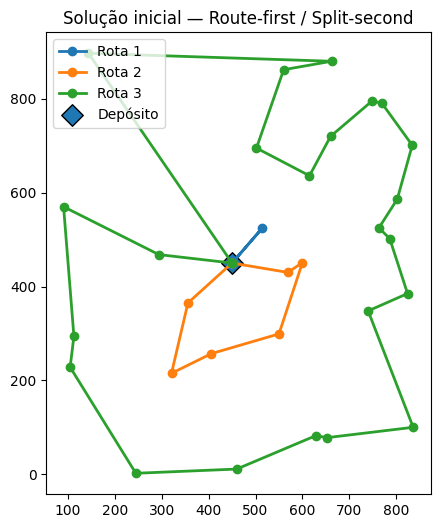

In [15]:
perm0 = permutacao_vizinho_mais_proximo(
    instancia
)

S0_split = split_otimo(
    instancia,
    perm0
)

print(
    "Custo da giant tour após Split:",
    S0_split.custo()
)

plot_prv(
    S0_split,
    "Solução inicial — Route-first / Split-second"
)



## 3.3 Movimentos sobre a permutação

Agora os operadores deixam de conhecer as rotas.

Usaremos:

- `swap`;
- `relocate`;
- inversão de segmento.

Depois de cada movimento, o Split recalcula os pontos de corte ótimos.

Portanto, um movimento pequeno na permutação pode alterar simultaneamente:

- a ordem de visita;
- os pontos de corte;
- a atribuição dos clientes aos veículos.


In [16]:
def aplicar_movimento_permutacao(
    permutacao,
    movimento
):
    tipo, i, j = movimento

    nova = permutacao.copy()

    if tipo == "swap":
        nova[i], nova[j] = (
            nova[j],
            nova[i]
        )

    elif tipo == "relocate":
        cliente = nova.pop(i)

        nova.insert(
            j,
            cliente
        )

    elif tipo == "reverse":
        a, b = sorted(
            (i, j)
        )

        nova[a:b + 1] = reversed(
            nova[a:b + 1]
        )

    else:
        raise ValueError(
            "Tipo de movimento inválido."
        )

    return nova


def movimento_permutacao_aleatorio(
    n,
    rng
):
    tipo = rng.choice(
        ["swap", "relocate", "reverse"]
    )

    i, j = rng.sample(
        range(n),
        2
    )

    return (
        tipo,
        i,
        j
    )


def vizinho_permutacao_aleatorio(
    permutacao,
    rng
):
    movimento = movimento_permutacao_aleatorio(
        len(permutacao),
        rng
    )

    return (
        aplicar_movimento_permutacao(
            permutacao,
            movimento
        ),
        movimento
    )


## 3.4 Recozimento Simulado sobre giant tours

O mecanismo do SA é exatamente o mesmo.

A diferença está na função de avaliação:

$$
\pi
\rightarrow
\operatorname{Split}(\pi)
\rightarrow
f(\pi).
$$

Assim, uma única avaliação é mais cara do que na representação por rotas, pois exige
resolver uma programação dinâmica.


In [17]:
def sa_split(
    prv,
    tempo_max=2.0,
    iter_max=100000,
    fator_resfriamento=0.999,
    seed=1
):
    rng = random.Random(seed)

    atual = permutacao_vizinho_mais_proximo(
        prv
    )

    custo_atual = custo_permutacao(
        prv,
        atual
    )

    melhor = atual.copy()
    melhor_custo = custo_atual

    inicio = time.perf_counter()
    historico = []

    iteracao = 0

    while (
        iteracao < iter_max
        and time.perf_counter() - inicio < tempo_max
    ):
        iteracao += 1

        temperatura = temperatura_geometrica(
            prv,
            iteracao,
            fator_resfriamento
        )

        candidata, movimento = (
            vizinho_permutacao_aleatorio(
                atual,
                rng
            )
        )

        custo_candidata = custo_permutacao(
            prv,
            candidata
        )

        delta = (
            custo_candidata
            - custo_atual
        )

        aceitou = (
            delta <= 0
            or rng.random()
            < math.exp(
                -delta
                / max(temperatura, 1e-12)
            )
        )

        if aceitou:
            atual = candidata
            custo_atual = custo_candidata

            if custo_atual < melhor_custo:
                melhor = atual.copy()
                melhor_custo = custo_atual

        historico.append({
            "iteracao": iteracao,
            "custo_atual": custo_atual,
            "melhor_custo": melhor_custo,
            "temperatura": temperatura,
            "movimento": movimento
        })

    return (
        split_otimo(
            prv,
            melhor
        ),
        melhor,
        historico
    )


SA — giant tour + Split: 4782.419222827158
Clientes=30 | Veículos=3 | Custo=4782.42


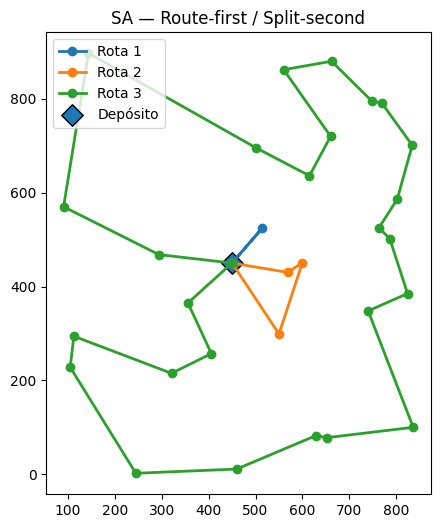

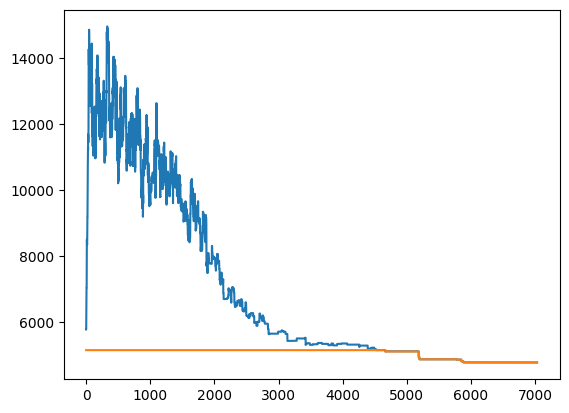

In [35]:
S_sa_split, perm_sa, hist_sa_split = sa_split(
    instancia,
    tempo_max=5,
    seed=10
)

print(
    "SA — giant tour + Split:",
    S_sa_split.custo()
)

plot_prv(
    S_sa_split,
    "SA — Route-first / Split-second"
)

plt.plot(
    [h["iteracao"] for h in hist_sa_split],
    [h["custo_atual"] for h in hist_sa_split],
    label="SA — Split"
)

plt.plot(
    [h["iteracao"] for h in hist_sa_split],
    [h["melhor_custo"] for h in hist_sa_split],
    label="SA — Split"
)

## 3.5 Busca Tabu sobre giant tours

Uma vizinhança completa com `swap`, `relocate` e inversão possui ordem $O(n^2)$
movimentos.

Como **cada vizinho exige executar o Split**, materializar e avaliar toda essa
vizinhança pode ser caro.

Por isso usaremos uma **Busca Tabu com vizinhança amostrada**:

1. geramos uma amostra de movimentos;
2. removemos movimentos tabu, exceto por aspiração;
3. escolhemos o melhor candidato da amostra.

O princípio da Busca Tabu é preservado, mas o custo por iteração fica controlado.


In [19]:
def amostrar_movimentos_permutacao(
    n,
    quantidade,
    rng
):
    movimentos = set()

    tentativas = 0
    limite = max(
        quantidade * 10,
        100
    )

    while (
        len(movimentos) < quantidade
        and tentativas < limite
    ):
        movimentos.add(
            movimento_permutacao_aleatorio(
                n,
                rng
            )
        )

        tentativas += 1

    return list(
        movimentos
    )


def movimento_inverso_tabu(
    movimento
):
    tipo, i, j = movimento

    if tipo == "relocate":
        return (
            tipo,
            j,
            i
        )

    return (
        tipo,
        min(i, j),
        max(i, j)
    )


def normalizar_movimento_tabu(
    movimento
):
    tipo, i, j = movimento

    if tipo in (
        "swap",
        "reverse"
    ):
        return (
            tipo,
            min(i, j),
            max(i, j)
        )

    return movimento


def tabu_split(
    prv,
    tempo_max=2.0,
    tamanho_tabu=12,
    tamanho_vizinhanca=100,
    iter_max=10000,
    seed=1
):
    rng = random.Random(seed)

    atual = permutacao_vizinho_mais_proximo(
        prv
    )

    custo_atual = custo_permutacao(
        prv,
        atual
    )

    melhor = atual.copy()
    melhor_custo = custo_atual

    tabu = collections.deque(
        maxlen=tamanho_tabu
    )

    inicio = time.perf_counter()
    historico = []

    iteracao = 0

    while (
        iteracao < iter_max
        and time.perf_counter() - inicio < tempo_max
    ):
        iteracao += 1

        movimentos = amostrar_movimentos_permutacao(
            len(atual),
            tamanho_vizinhanca,
            rng
        )

        melhor_candidata = None
        melhor_custo_candidata = float("inf")
        melhor_movimento = None

        for movimento in movimentos:
            candidata = aplicar_movimento_permutacao(
                atual,
                movimento
            )

            custo = custo_permutacao(
                prv,
                candidata
            )

            atributo = normalizar_movimento_tabu(
                movimento
            )

            movimento_tabu = (
                atributo in tabu
            )

            aspiracao = (
                custo < melhor_custo
            )

            if (
                movimento_tabu
                and not aspiracao
            ):
                continue

            if custo < melhor_custo_candidata:
                melhor_candidata = candidata
                melhor_custo_candidata = custo
                melhor_movimento = movimento

        if melhor_candidata is None:
            break

        atual = melhor_candidata
        custo_atual = melhor_custo_candidata

        if custo_atual < melhor_custo:
            melhor = atual.copy()
            melhor_custo = custo_atual

        tabu.append(
            normalizar_movimento_tabu(
                movimento_inverso_tabu(
                    melhor_movimento
                )
            )
        )

        historico.append({
            "iteracao": iteracao,
            "custo_atual": custo_atual,
            "melhor_custo": melhor_custo,
            "movimento": melhor_movimento
        })

    return (
        split_otimo(
            prv,
            melhor
        ),
        melhor,
        historico
    )


Tabu — giant tour + Split: 4766.5830548066515
Clientes=30 | Veículos=3 | Custo=4766.58


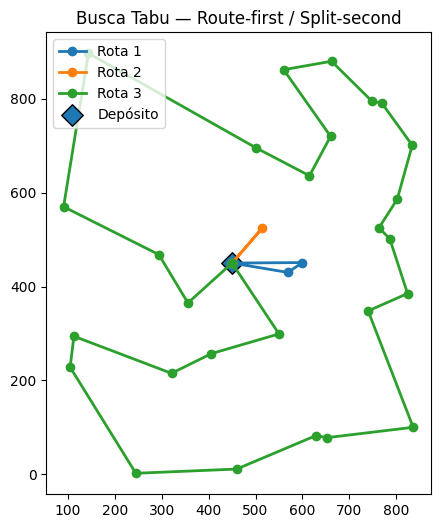

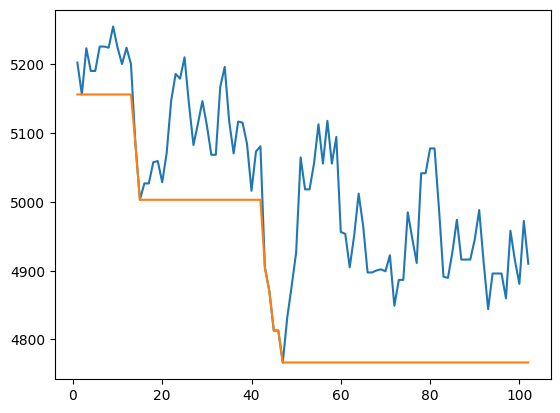

In [36]:
S_tabu_split, perm_tabu, hist_tabu_split = tabu_split(
    instancia,
    tempo_max=5,
    tamanho_tabu=12,
    tamanho_vizinhanca=80,
    seed=10
)

print(
    "Tabu — giant tour + Split:",
    S_tabu_split.custo()
)

plot_prv(
    S_tabu_split,
    "Busca Tabu — Route-first / Split-second"
)


plt.plot(
    [h["iteracao"] for h in hist_tabu_split],
    [h["custo_atual"] for h in hist_tabu_split],
    label="Tabu — Split"
)

plt.plot(
    [h["iteracao"] for h in hist_tabu_split],
    [h["melhor_custo"] for h in hist_tabu_split],
    label="Tabu — Split"
)


# 4. Comparando as duas representações

Temos agora quatro combinações:

$$
\begin{array}{c|c|c}
&\text{Split-first / Route-second}
&\text{Route-first / Split-second}\\
\hline
\text{SA}
&\text{SA sobre rotas}
&\text{SA sobre permutação + Split}\\
\text{Tabu}
&\text{Tabu sobre rotas}
&\text{Tabu sobre permutação + Split}
\end{array}
$$

A comparação não deve considerar apenas o custo final.

A segunda representação possui uma avaliação mais cara, porque cada candidato
aciona o Split. Por outro lado, uma pequena mudança na permutação pode induzir uma
mudança maior na distribuição entre veículos.

Isso produz um trade-off:

$$
\boxed{
\text{avaliações mais caras}
\quad\text{versus}\quad
\text{decoder mais poderoso}
}
$$


In [38]:
resultados = [
    (
        "SA — rotas",
        S_sa_rotas.custo(),
        len(hist_sa_rotas)
    ),
    (
        "Tabu — rotas",
        S_tabu_rotas.custo(),
        len(hist_tabu_rotas)
    ),
    (
        "SA — giant tour + Split",
        S_sa_split.custo(),
        len(hist_sa_split)
    ),
    (
        "Tabu — giant tour + Split",
        S_tabu_split.custo(),
        len(hist_tabu_split)
    )
]

print(
    f"{'Método':32s} | {'Custo':>10s} | {'Iterações':>10s}"
)

print(
    "-" * 60
)

for nome, custo, iteracoes in resultados:
    print(
        f"{nome:32s} | "
        f"{custo:10.2f} | "
        f"{iteracoes:10d}"
    )


Método                           |      Custo |  Iterações
------------------------------------------------------------
SA — rotas                       |    4766.58 |      21261
Tabu — rotas                     |    5253.07 |         37
SA — giant tour + Split          |    4782.42 |       7030
Tabu — giant tour + Split        |    4766.58 |        102


## Síntese conceitual

### Split-first / Route-second

A solução explicita diretamente

$$
(r_1,\ldots,r_R).
$$

**Vantagens**

- avaliação de custo barata;
- representação visual e intuitiva;
- movimentos têm interpretação direta em termos de veículos.

**Desvantagens**

- precisamos de operadores específicos para alterar a atribuição entre veículos;
- a qualidade do particionamento inicial pode influenciar bastante a busca.

### Route-first / Split-second

A solução manipulada é

$$
\pi=(\pi_1,\ldots,\pi_n).
$$

**Vantagens**

- operadores simples de permutação;
- a melhor divisão da ordem é resolvida exatamente;
- um movimento pode alterar implicitamente a atribuição entre veículos.

**Desvantagens**

- cada avaliação é mais cara;
- uma alteração pequena no genótipo pode provocar uma mudança relativamente grande
  no conjunto de rotas.

A comparação mostra que a **representação da solução é parte do projeto da
metaheurística**, e não apenas um detalhe de programação.


# 5. Exercícios

Os três primeiros exercícios formam a lista regular. Os dois últimos são adicionais
para pós-graduação.


## Exercício 1 — ILS ou VNS sobre rotas explícitas

Implemente uma das seguintes metaheurísticas utilizando a representação
Split-first / Route-second:

- Iterated Local Search (ILS); ou
- Variable Neighborhood Search (VNS).

Utilize os movimentos:

- swap;
- relocate;
- inversão.

Compare o resultado com SA e Busca Tabu na mesma instância.

Discuta o papel de cada movimento na intensificação e na diversificação.


## Exercício 2 — A mesma metaheurística nas duas representações

Escolha **SA ou Busca Tabu** e compare:

1. versão sobre rotas explícitas;
2. versão sobre giant tour + Split.

Utilize pelo menos 10 sementes e várias instâncias.

Adote o mesmo limite de tempo por execução.

Registre:

- média;
- desvio-padrão;
- melhor resultado;
- pior resultado;
- tempo;
- número de iterações.

Discuta:

1. qual representação encontra melhores soluções?
2. qual executa mais iterações por segundo?
3. o Split compensa seu custo adicional?
4. a resposta muda com o tamanho da instância?


## Exercício 3 — Parametrização

Escolha uma das quatro combinações estudadas:

- SA sobre rotas;
- Tabu sobre rotas;
- SA + Split;
- Tabu + Split.

Estude experimentalmente seus principais parâmetros.

Para SA:

- fator de resfriamento;
- temperatura inicial;
- composição dos movimentos.

Para Tabu:

- tamanho da lista tabu;
- tamanho da vizinhança;
- critério de parada.

Faça múltiplas execuções e apresente média, desvio-padrão, melhor resultado e tempo.


# Exercícios adicionais — Pós-graduação

## Exercício 4 — Busca Tabu completa versus amostrada

Na representação Route-first / Split-second utilizamos uma vizinhança amostrada
porque cada avaliação é relativamente cara.

Implemente uma versão que avalie uma vizinhança completa de pelo menos um operador,
por exemplo todos os movimentos `swap`.

Compare:

$$
\text{Tabu completa}
\qquad\text{versus}\qquad
\text{Tabu amostrada}.
$$

Analise:

- qualidade final;
- tempo por iteração;
- número de iterações;
- número de avaliações.

Discuta em quais tamanhos de instância a amostragem se torna vantajosa.


## Exercício 5 — Split capacitado

Introduza demandas $q_i$ e capacidade $Q$.

Adapte o algoritmo Split para permitir o segmento

$$
\pi_i,\ldots,\pi_j
$$

somente se

$$
\sum_{t=i}^{j}q_{\pi_t}\leq Q.
$$

Depois aplique **SA sobre a giant tour** utilizando esse decoder capacitado.

Compare:

1. número de rotas utilizado;
2. qualidade das soluções;
3. custo computacional por avaliação.

Discuta por que a estratégia Route-first / Split-second é particularmente atraente
quando o decoder pode tratar diretamente restrições de viabilidade.
